In [ ]:

# STEP 1: Download SMS Spam Collection Dataset

import pandas as pd
import requests
import zipfile
import io
import os

# Official UCI dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

print("Downloading dataset...")

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("\nDataset downloaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())



Dataset downloaded successfully!
Dataset shape: (5572, 2)

First 5 records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64


In [ ]:

# STEP 2: Text Preprocessing and TF-IDF Feature Extraction

import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text to lowercase and remove unnecessary characters
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Apply preprocessing
df["clean_message"] = df["message"].apply(preprocess_text)

# Separate features and target
X = df["clean_message"]
y = df["label"].map({"ham": 0, "spam": 1})

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Preprocessing completed successfully!")
print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("TF-IDF features:", X_train_tfidf.shape[1])
print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)
print("\nClass encoding: Ham = 0, Spam = 1")


Preprocessing completed successfully!
Training samples: 4457
Testing samples: 1115
TF-IDF features: 5000
Training feature matrix: (4457, 5000)
Testing feature matrix: (1115, 5000)

Class encoding: Ham = 0, Spam = 1


In [ ]:

# STEP 3: Train and Evaluate Four ML Classifiers

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Define four models
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ),

    "Naive Bayes": MultinomialNB()
}

# Store evaluation results
results = []
trained_models = {}
confusion_matrices = {}

# Train and evaluate
for name, model in models.items():

    print("\nTraining:", name)
    start_time = time.time()

    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_test_tfidf)

    elapsed = time.time() - start_time

    trained_models[name] = model

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Time (seconds)": elapsed
    })

    confusion_matrices[name] = confusion_matrix(
        y_test, predictions
    )

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("Training + prediction time:", round(elapsed, 2), "seconds")

# Create comparison table
results_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========")
display(results_df.round(4))

# Identify best model by F1-score
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("\nBest model based on F1-score:")
print(best_model["Algorithm"])
print("F1-Score:", round(best_model["F1-Score"], 4))

# Save actual results
results_df.to_csv("model_comparison.csv", index=False)

print("\nResults saved successfully!")



Training: Decision Tree
Accuracy: 0.9677
Precision: 0.9185
Recall: 0.8322
F1-Score: 0.8732
Training + prediction time: 0.82 seconds

Training: KNN
Accuracy: 0.9767
Precision: 0.9843
Recall: 0.8389
F1-Score: 0.9058
Training + prediction time: 0.54 seconds

Training: SVM
Accuracy: 0.9839
Precision: 0.9925
Recall: 0.8859
F1-Score: 0.9362
Training + prediction time: 0.04 seconds

Training: Naive Bayes
Accuracy: 0.965
Precision: 1.0
Recall: 0.7383
F1-Score: 0.8494
Training + prediction time: 0.02 seconds

========== MODEL COMPARISON ==========


,Algorithm,Accuracy,Precision,Recall,F1-Score,Time (seconds)
0,Decision Tree,0.9677,0.9185,0.8322,0.8732,0.8158
1,KNN,0.9767,0.9843,0.8389,0.9058,0.5430
2,SVM,0.9839,0.9925,0.8859,0.9362,0.0353
3,Naive Bayes,0.9650,1.0000,0.7383,0.8494,0.0172



Best model based on F1-score:
SVM
F1-Score: 0.9362

Results saved successfully!


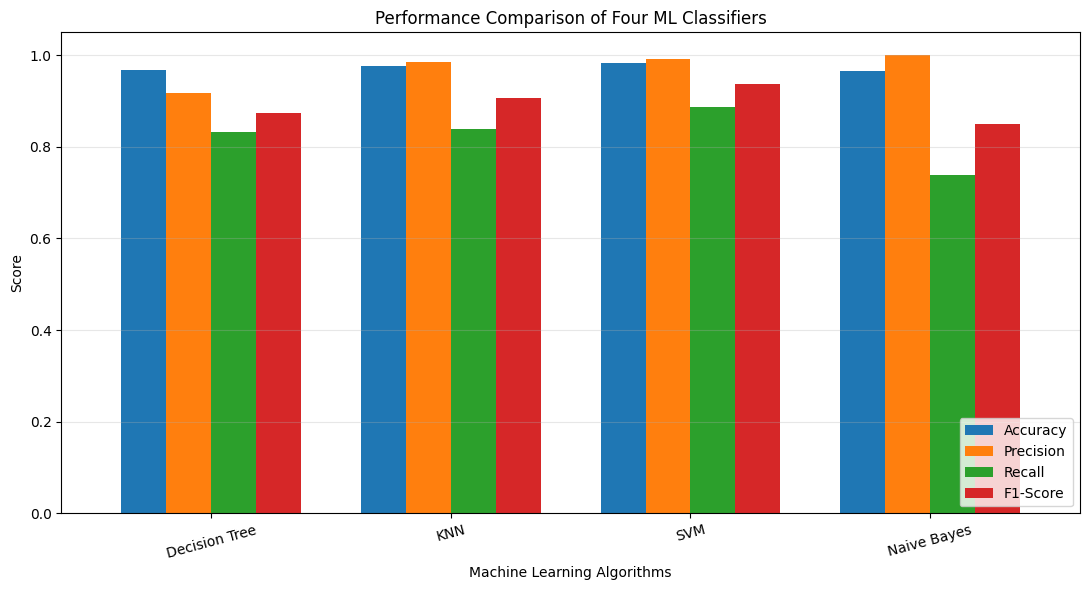

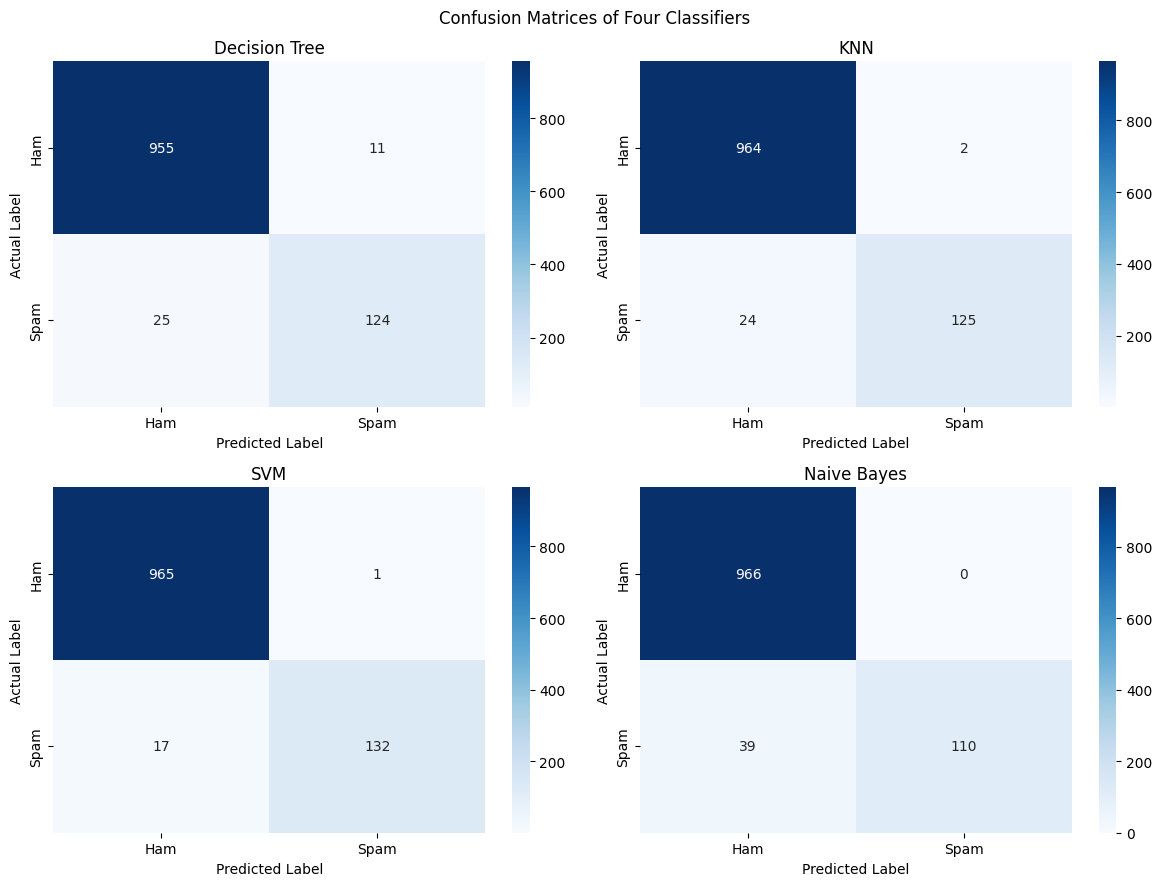


Classification Report: Decision Tree
              precision    recall  f1-score   support

         Ham       0.97      0.99      0.98       966
        Spam       0.92      0.83      0.87       149

    accuracy                           0.97      1115
   macro avg       0.95      0.91      0.93      1115
weighted avg       0.97      0.97      0.97      1115


Classification Report: KNN
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.98      0.84      0.91       149

    accuracy                           0.98      1115
   macro avg       0.98      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115


Classification Report: SVM
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.99      0.89      0.94       149

    accuracy                           0.98      1115
   macro avg       0.99      0.94 

In [ ]:

# STEP 4: Performance Graphs and Confusion Matrices

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Performance comparison graph
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_df.set_index("Algorithm")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    width=0.75
)

plt.title("Performance Comparison of Four ML Classifiers")
plt.ylabel("Score")
plt.xlabel("Machine Learning Algorithms")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("comparison_graph.png", dpi=300)
plt.show()

# 2. Individual confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, cm) in zip(axes.flatten(), confusion_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices of Four Classifiers")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

# 3. Detailed classification reports
for name, model in trained_models.items():
    print("\nClassification Report:", name)
    print(classification_report(
        y_test,
        model.predict(X_test_tfidf),
        target_names=["Ham", "Spam"]
    ))

print("Graphs and confusion matrices saved successfully!")


In [5]:

# STEP 5: WHAT-IF EXPERIMENT - TF-IDF N-GRAM COMPARISON

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.base import clone

# New TF-IDF representation with bigrams
tfidf_bigram = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_bigram = tfidf_bigram.fit_transform(X_train)
X_test_bigram = tfidf_bigram.transform(X_test)

what_if_results = []

# Use the same four classifier configurations
for name, original_model in models.items():

    model = clone(original_model)

    model.fit(X_train_bigram, y_train)
    predictions = model.predict(X_test_bigram)

    what_if_results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

what_if_df = pd.DataFrame(what_if_results)

print("WHAT-IF EXPERIMENT: UNIGRAM + BIGRAM")
display(what_if_df.round(4))

# Compare baseline and what-if F1 scores
comparison = pd.DataFrame({
    "Algorithm": results_df["Algorithm"],
    "Baseline F1": results_df["F1-Score"],
    "Bigram F1": what_if_df["F1-Score"]
})

comparison["F1 Change"] = (
    comparison["Bigram F1"] - comparison["Baseline F1"]
)

print("\nBASELINE VS WHAT-IF COMPARISON")
display(comparison.round(4))

# Save experiment
what_if_df.to_csv("what_if_results.csv", index=False)
comparison.to_csv("baseline_vs_bigram.csv", index=False)

print("What-if experiment completed and saved!")


WHAT-IF EXPERIMENT: UNIGRAM + BIGRAM


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.9677,0.9065,0.8456,0.8750
1,KNN,0.9731,0.9760,0.8188,0.8905
2,SVM,0.9857,0.9854,0.9060,0.9441
3,Naive Bayes,0.9740,1.0000,0.8054,0.8922



BASELINE VS WHAT-IF COMPARISON


,Algorithm,Baseline F1,Bigram F1,F1 Change
0,Decision Tree,0.8732,0.8750,0.0018
1,KNN,0.9058,0.8905,-0.0153
2,SVM,0.9362,0.9441,0.0079
3,Naive Bayes,0.8494,0.8922,0.0428


What-if experiment completed and saved!


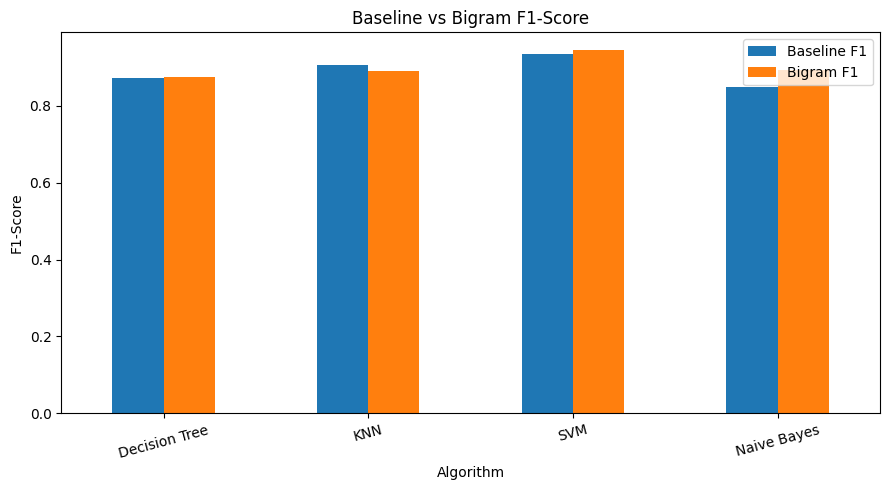

PROJECT PACKAGE CREATED SUCCESSFULLY!
Files included:
Text_Classification_Battle/README.md
Text_Classification_Battle/reports/experiment_report.txt
Text_Classification_Battle/reports/classification_reports.txt
Text_Classification_Battle/outputs/what_if_comparison.png
Text_Classification_Battle/outputs/what_if_results.csv
Text_Classification_Battle/outputs/baseline_results.csv
Text_Classification_Battle/outputs/svm_confusion_matrix.csv
Text_Classification_Battle/outputs/confusion_matrices.png
Text_Classification_Battle/outputs/comparison_graph.png
Text_Classification_Battle/outputs/knn_confusion_matrix.csv
Text_Classification_Battle/outputs/naive_bayes_confusion_matrix.csv
Text_Classification_Battle/outputs/decision_tree_confusion_matrix.csv
Text_Classification_Battle/outputs/baseline_vs_bigram.csv

ZIP: Text_Classification_Battle_Submission.zip


In [6]:

# STEP 6: FINAL PROJECT FILES AND SUBMISSION PACKAGE

import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

os.makedirs("Text_Classification_Battle/outputs", exist_ok=True)
os.makedirs("Text_Classification_Battle/reports", exist_ok=True)

base = "Text_Classification_Battle"
out = base + "/outputs"

# Save experimental results
results_df.to_csv(out + "/baseline_results.csv", index=False)
what_if_df.to_csv(out + "/what_if_results.csv", index=False)
comparison.to_csv(out + "/baseline_vs_bigram.csv", index=False)

# Save baseline confusion matrices
for name, cm in confusion_matrices.items():
    filename = name.lower().replace(" ", "_")
    pd.DataFrame(
        cm,
        index=["Actual_Ham", "Actual_Spam"],
        columns=["Predicted_Ham", "Predicted_Spam"]
    ).to_csv(out + "/" + filename + "_confusion_matrix.csv")

# Save baseline and what-if comparison graph
comparison_plot = comparison.set_index("Algorithm")[
    ["Baseline F1", "Bigram F1"]
]
comparison_plot.plot(kind="bar", figsize=(9, 5))
plt.title("Baseline vs Bigram F1-Score")
plt.ylabel("F1-Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(out + "/what_if_comparison.png", dpi=300)
plt.show()
plt.close()

# Save classification reports
with open(base + "/reports/classification_reports.txt", "w") as f:
    for name, model in trained_models.items():
        f.write("\n" + name + "\n")
        f.write(classification_report(
            y_test,
            model.predict(X_test_tfidf),
            target_names=["Ham", "Spam"]
        ))
        f.write("\n")

# Save experiment report
best = what_if_df.loc[what_if_df["F1-Score"].idxmax()]

report = f"""
TEXT CLASSIFICATION BATTLE
SMS SPAM DETECTION USING MACHINE LEARNING

1. PROBLEM STATEMENT
Classify SMS messages into Ham (legitimate) and Spam (unwanted).

2. DATASET
SMS Spam Collection Dataset
Total records: {len(df)}
Ham: {(df['label'] == 'ham').sum()}
Spam: {(df['label'] == 'spam').sum()}

3. PREPROCESSING
- Lowercase conversion
- Punctuation removal
- Whitespace cleaning
- TF-IDF feature extraction
- 80:20 stratified train-test split
- Random state: 42

4. ALGORITHMS
Decision Tree, KNN, Linear SVM, Multinomial Naive Bayes.

5. BASELINE EXPERIMENT
TF-IDF Unigrams (1,1)

{results_df.to_string(index=False)}

6. WHAT-IF EXPERIMENT
TF-IDF Unigrams + Bigrams (1,2)

{what_if_df.to_string(index=False)}

7. FINAL RECOMMENDATION
Best algorithm by F1-score: {best['Algorithm']}
Accuracy: {best['Accuracy']:.4f}
Precision: {best['Precision']:.4f}
Recall: {best['Recall']:.4f}
F1-score: {best['F1-Score']:.4f}

8. CONCLUSION
The experimental results show that SVM with TF-IDF
unigrams and bigrams achieved the highest F1-score.
Adding bigrams improved the performance of SVM,
Decision Tree and Naive Bayes, while KNN performed
better with unigrams.

All reported results were obtained from the student's
own experimental execution.
"""

with open(base + "/reports/experiment_report.txt", "w") as f:
    f.write(report)

# Create README
readme = """
# Text Classification Battle – SMS Spam Detection

## Problem Statement
Classify SMS messages into Ham and Spam using machine learning.

## Dataset
UCI SMS Spam Collection Dataset.

## Algorithms
1. Decision Tree
2. K-Nearest Neighbours
3. Support Vector Machine
4. Multinomial Naive Bayes

## Technologies
Python, Pandas, Scikit-learn, Matplotlib, Seaborn.

## Methodology
Text preprocessing, TF-IDF feature extraction and stratified
80:20 train-test split.

## Evaluation Metrics
Accuracy, Precision, Recall and F1-score.

## What-if Experiment
Compared TF-IDF unigrams (1,1) against unigrams + bigrams (1,2).

## Best Configuration
SVM with unigrams + bigrams, selected based on experimental F1-score.

## Outputs
See the outputs folder for CSV results, graphs and confusion matrices.

## Reports
See the reports folder for classification reports and experiment summary.
"""

with open(base + "/README.md", "w") as f:
    f.write(readme)

# Copy baseline graph if already generated
if os.path.exists("comparison_graph.png"):
    shutil.copy("comparison_graph.png", out)

if os.path.exists("confusion_matrices.png"):
    shutil.copy("confusion_matrices.png", out)

# Package the project
shutil.make_archive(
    "Text_Classification_Battle_Submission",
    "zip",
    base
)

print("PROJECT PACKAGE CREATED SUCCESSFULLY!")
print("Files included:")
for root, dirs, files in os.walk(base):
    for file in files:
        print(os.path.join(root, file))

print("\nZIP: Text_Classification_Battle_Submission.zip")


In [7]:
from google.colab import files

files.download("Text_Classification_Battle_Submission.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>